# Supplementary Fig S4 · Retrieval accuracy in detail

Merges the accuracy panels of the old Figs S2 and S3 (`_backup_2026-11-03/S2_whole_tile.ipynb` B–C,
`_backup_2026-11-03/S3_gene_set.ipynb` A–C); the query-log times (old S2A, S3D) are now supplementary Tables S3–S4 and
the storage (old S3E) Table S1.

* **A** the typical breast complete query: the exact d_B of every index tile (gray) and of the tiles Spindle returned;
  dashed, the distance of the c-th nearest index tile at c = 5 % of n.
* **B** RDE and NNR of Spindle against the search breadth g (default 0.25), every dataset, mean ± s.d. over seeds.
* **C** the typical breast partial query (|S| = 16), as A with d_B^S.
* **D, E** RDE and NNR against |S|: Spindle, padding + Spindle-naive, imputation + Spindle-naive; per seed the median
  over the eight datasets, mean ± s.d. over seeds.

**Run first:** `R2_whole_tile` (`results/whole_tile/`), `R3_gene_set` (`results/gene_set/`).
Writes `figures/figS4_accuracy/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

import retrieval as rt
import style as ps

FIG = "figS4_accuracy"
KEYS = ps.DATASET_ORDER
G = 0.25
SP_WHOLE, SP_PART = ps.TIER_COLORS["spindle"], ps.TIER_COLORS["spindle_partial"]
BASE = {"padding": "#44AA99", "imputation": "#882255"}
METHOD_LABEL = {"spindle_partial": "Spindle-Partial", "padding": "Padding + Spindle-naive",
                "imputation": "Imputation + Spindle-naive"}
MARK = {"spindle_partial": "^", "padding": "s", "imputation": "o"}
COLOR = {"spindle_partial": SP_PART, **BASE}
H1, H2 = 62.0, 56.0
TOP, BOTTOM = 6.0, 10.0
LEG_H = 9.0

nx = pd.read_csv(ROOT / "results" / "whole_tile" / "nx.csv")
nx_size = pd.read_csv(ROOT / "results" / "gene_set" / "nx_size.csv")
print(sorted(set(nx.tag) | set(nx_size.tag)))


def ax_mm(fig, x, y, w, h):
    """Axes at (x, y) mm from the panel's bottom-left corner, w x h mm."""
    W, H = ps.size_mm(fig)
    return fig.add_axes([x / W, y / H, w / W, h / H])


def band(fig, z, color, xlabel, title, bottom, top):
    d, found = z["d"], z["found"]
    c = rt.c5(len(d))
    d_c = np.sort(d)[c - 1]
    print(f"{title}: N = {len(d)}, returned {len(found)}, c = {c}, d_c = {d_c:.3f}")
    ax = ps.axes(fig, left=11.0, right=2.0, bottom=bottom, top=top)
    bins = np.linspace(d.min(), np.quantile(d, 0.995), 50)
    n_all, _, _ = ax.hist(d, bins=bins, color=ps.LIGHT, lw=0, zorder=2)
    ax.hist(d[found], bins=bins, color=color, lw=0, zorder=3)
    ax.axvline(d_c, ls="--", lw=0.75, color=ps.INK, zorder=4)
    ax.text(d_c, 0.99, " c = 5 % of n", transform=ax.get_xaxis_transform(), ha="left", va="top", fontsize=ps.TICK_PT)
    ax.set_ylim(0, 1.15 * n_all.max())
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Index tiles")
    ax.set_xlim(bins[0], bins[-1])
    W, H = ps.size_mm(fig)
    fig.text(11.0 / W, 1 - 0.5 / H, f"{title} (n = {len(d):,})", va="top", fontsize=ps.TICK_PT)
    handles = [Line2D([], [], ls="", marker="s", ms=3.5, color=ps.LIGHT, label="All index tiles"),
               Line2D([], [], ls="", marker="s", ms=3.5, color=color, label=f"Returned ({len(found)})")]
    fig.legend(handles=handles, ncol=1, loc="lower left", bbox_to_anchor=(11.0 / W, 0.0))

['method-v2']


## A · The typical breast complete query

Breast, complete query: N = 1840, returned 484, c = 92, d_c = 0.749
figures/figS4_accuracy/panels/A.pdf/.png: 62 x 62 mm, 0.0 / 0.2 MB


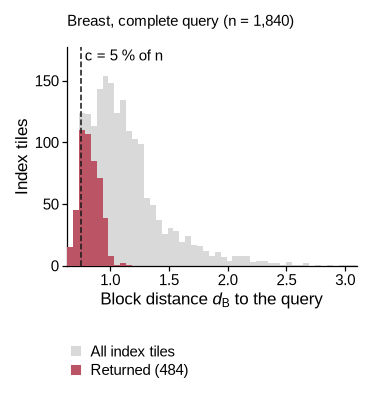

In [2]:
def panel_a(fig):
    band(fig, np.load(ROOT / "results" / "whole_tile" / "band" / "breast_cancer.npz"), SP_WHOLE,
         r"Block distance $d_{\mathcal{B}}$ to the query", "Breast, complete query", BOTTOM + LEG_H, TOP)


fig = ps.panel(62, H1); panel_a(fig); ps.save_panel(fig, FIG, "A")

## B · RDE and NNR against the search breadth g

figures/figS4_accuracy/panels/B.pdf/.png: 118 x 62 mm, 0.0 / 0.5 MB


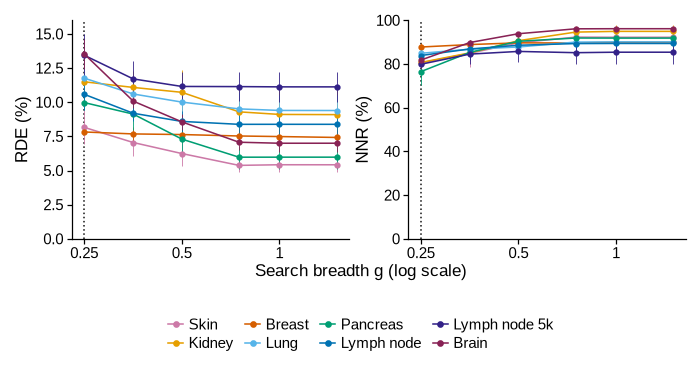

In [3]:
GS = sorted(nx.g.unique())
G_HANDLES = [Line2D([], [], marker="o", ms=2.2, lw=0.75, color=ps.DATASET_COLORS[k], label=ps.DATASET_LABELS[k])
             for k in KEYS]


def panel_b(fig):
    W, H = ps.size_mm(fig)
    w = (W - 4.0) / 2
    for j, (col, ylabel, ylim) in enumerate((("NX5", "RDE (%)", (0, 16)), ("overlap5", "NNR (%)", (0, 100)))):
        ax = ax_mm(fig, 10.0 + j * w, BOTTOM + LEG_H, w - 10.0, H - BOTTOM - LEG_H - TOP)
        for k in KEYS:
            s = nx[nx.key == k].sort_values("g")
            ax.errorbar(s.g, 100 * s[col], yerr=100 * s[f"{col}_sd"], fmt="-o", ms=2.0, lw=0.75,
                        color=ps.DATASET_COLORS[k], elinewidth=0.4, zorder=3)
        ax.axvline(G, ls=":", lw=0.75, color=ps.INK, zorder=1)
        ax.set_xscale("log", base=2)
        ax.set_xticks([0.25, 0.5, 1.0], ["0.25", "0.5", "1"])
        ax.minorticks_off()
        ax.set_ylim(*ylim)
        ax.set_ylabel(ylabel)
    fig.text(0.5, (BOTTOM + LEG_H - 7.0) / H, "Search breadth g (log scale)", ha="center", va="bottom")
    fig.legend(handles=G_HANDLES, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 0.0), columnspacing=0.8,
               handlelength=1.0)


fig = ps.panel(118, H1); panel_b(fig); ps.save_panel(fig, FIG, "B")

## C · The typical breast partial query, |S| = 16

Breast, partial query, |S| = 16: N = 1840, returned 309, c = 92, d_c = 0.298
figures/figS4_accuracy/panels/C.pdf/.png: 62 x 56 mm, 0.0 / 0.2 MB


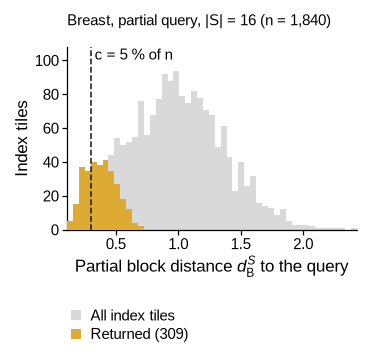

In [4]:
def panel_c(fig):
    band(fig, np.load(ROOT / "results" / "gene_set" / "band" / "breast_cancer.npz"), SP_PART,
         r"Partial block distance $d^{S}_{\mathcal{B}}$ to the query", "Breast, partial query, |S| = 16",
         BOTTOM + LEG_H, TOP)


fig = ps.panel(62, H2); panel_c(fig); ps.save_panel(fig, FIG, "C")

## D, E · RDE and NNR against |S|

figures/figS4_accuracy/panels/D.pdf/.png: 59 x 56 mm, 0.0 / 0.2 MB
figures/figS4_accuracy/panels/E.pdf/.png: 59 x 56 mm, 0.0 / 0.2 MB


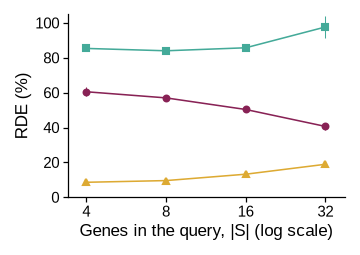

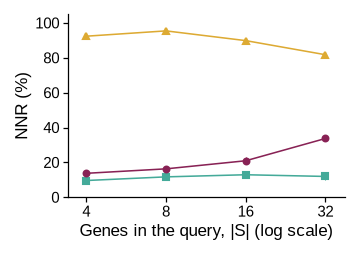

In [5]:
SIZE_HANDLES = [Line2D([], [], marker=MARK[m], ms=2.8, color=COLOR[m], label=METHOD_LABEL[m])
                for m in ("spindle_partial", "padding", "imputation")]


def by_size(fig, col, ylabel):
    ax = ps.axes(fig, left=10.0, right=2.0, bottom=BOTTOM + LEG_H, top=TOP)
    t = nx_size[nx_size["size"] > 0]
    for m in ("padding", "imputation", "spindle_partial"):
        s = t[t.method == m].sort_values("size")
        ax.errorbar(s["size"], 100 * s[col], yerr=100 * s[f"{col}_sd"], fmt=f"-{MARK[m]}", ms=2.8, color=COLOR[m],
                    elinewidth=0.5, zorder=3 if m == "spindle_partial" else 2)
    ax.set_xscale("log", base=2)
    ax.set_xticks([4, 8, 16, 32], ["4", "8", "16", "32"])
    ax.minorticks_off()
    ax.set_xlim(3.4, 38)
    ax.set_ylim(0, 105)
    ax.set_xlabel("Genes in the query, |S| (log scale)")
    ax.set_ylabel(ylabel)


def panel_d(fig):
    by_size(fig, "NX5", "RDE (%)")


def panel_e(fig):
    by_size(fig, "overlap5", "NNR (%)")


def size_legend(fig):
    fig.legend(handles=SIZE_HANDLES, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 0.0))


fig = ps.panel(59, H2); panel_d(fig); ps.save_panel(fig, FIG, "D")
fig = ps.panel(59, H2); panel_e(fig); ps.save_panel(fig, FIG, "E")

## Full figure

Breast, complete query: N = 1840, returned 484, c = 92, d_c = 0.749
Breast, partial query, |S| = 16: N = 1840, returned 309, c = 92, d_c = 0.298
figures/figS4_accuracy/figS4_accuracy.pdf/.png: 180 x 121 mm, 0.0 / 1.5 MB


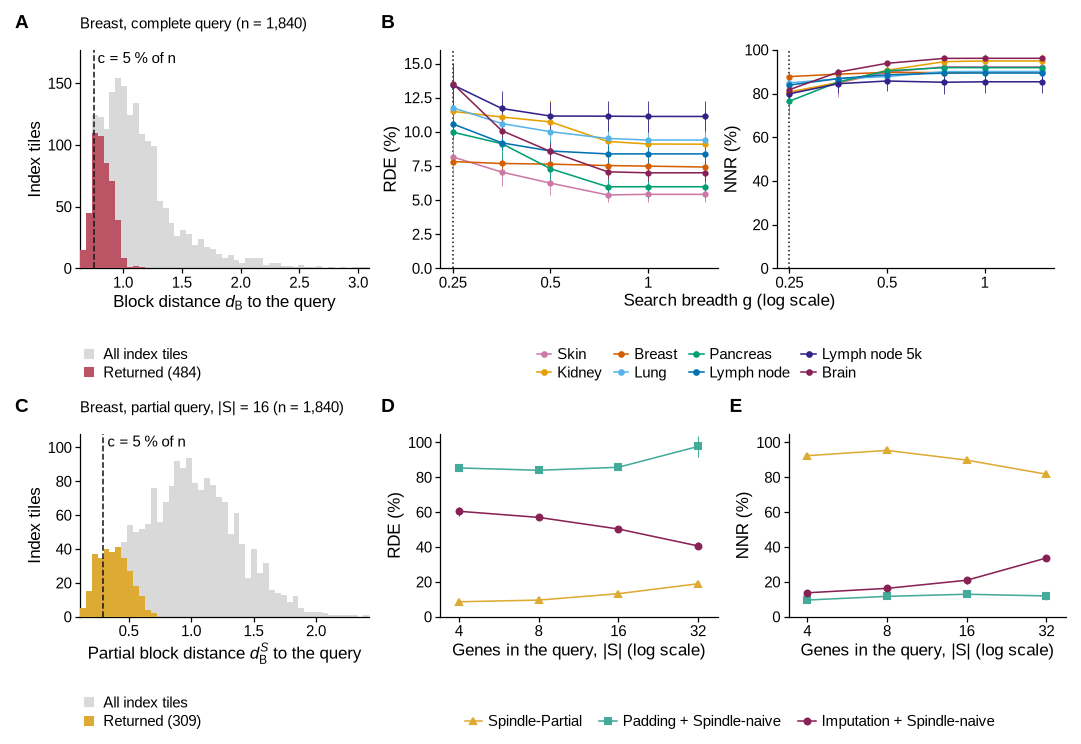

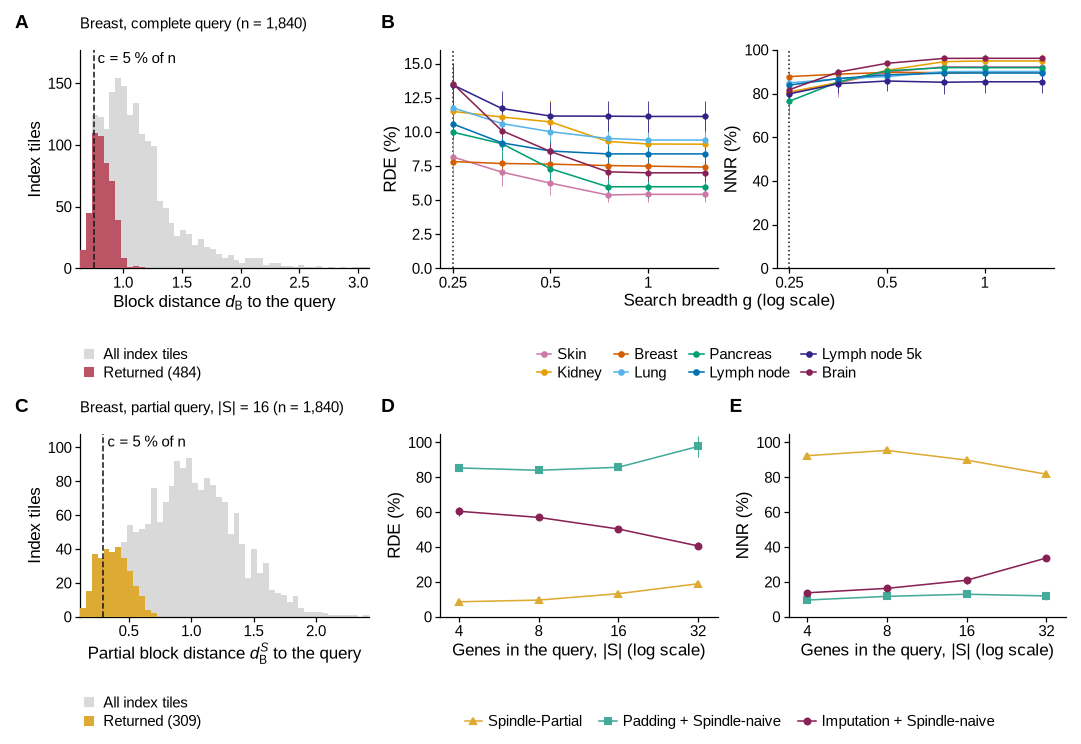

In [6]:
Y2 = H1 + 3.0
page = ps.page(180, Y2 + H2)
panel_a(ps.place(page, "A", 0, 0, 62, H1))
panel_b(ps.place(page, "B", 62, 0, 118, H1))
panel_c(ps.place(page, "C", 0, Y2, 62, H2))
panel_d(ps.place(page, "D", 62, Y2, 59, H2))
panel_e(ps.place(page, "E", 121, Y2, 59, H2))
size_legend(ps.place(page, None, 62, Y2 + H2 - LEG_H + 1.0, 118, LEG_H - 1.0))
ps.save_figure(page, FIG)
page